# Skin Disorder Classification and Data Analysis

**Project:** PRCP-1027 - Skin Disorder Prediction  
**Goal:** Explore the supplied dermatology dataset, compare machine-learning classifiers, and document responsible next steps.

This notebook is the complete analysis and report. It predicts one of six labels in a small, historical dataset. The models are educational prototypes, **not diagnostic devices**; results must not be used to diagnose or treat patients.

## Objectives
1. Check the data and describe its quality and class distribution.
2. Compare several classifiers using leakage-safe validation.
3. Evaluate the cross-validation winner once on a held-out test set.
4. Discuss a clinical-features-only experiment, practical limitations, and responsible follow-up.

The project brief describes 34 predictors: 11 clinical signs, 22 histopathological findings, and Age. The target is `class`. Class labels follow the names in the project brief: 1 Psoriasis, 2 Seborrheic dermatitis, 3 Lichen planus, 4 Pityriasis rosea, 5 Chronic dermatitis, and 6 Pityriasis rubra pilaris.


## 1. Set up the analysis

**Why:** Import the common analysis and scikit-learn tools once, and set a fixed seed so the split and model comparisons can be reproduced. The notebook uses only standard data-science packages.


In [22]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import (
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    RandomForestClassifier,
)
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import (
    RepeatedStratifiedKFold,
    cross_validate,
    train_test_split,
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

RANDOM_STATE = 42
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)
sns.set_theme(style="whitegrid")


## 2. Load the supplied CSV

**Why:** Read the file from the notebook's folder and interpret the dataset's `?` marker as missing data. A clear file check prevents accidentally analyzing a different dataset or a missing path.


In [23]:
DATA_PATH = Path("dataset_35_dermatology (1).csv")
if not DATA_PATH.is_file():
    raise FileNotFoundError(
        f"Could not find {DATA_PATH.resolve()}. Keep the supplied CSV beside this notebook."
    )

df = pd.read_csv(DATA_PATH, na_values=["?"])
print(f"Dataset shape: {df.shape[0]} rows x {df.shape[1]} columns")
display(df.head())


Dataset shape: 366 rows x 35 columns


,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_and_elbow_involvement,scalp_involvement,family_history,melanin_incontinence,eosinophils_in_the_infiltrate,PNL_infiltrate,fibrosis_of_the_papillary_dermis,exocytosis,acanthosis,hyperkeratosis,parakeratosis,clubbing_of_the_rete_ridges,elongation_of_the_rete_ridges,thinning_of_the_suprapapillary_epidermis,spongiform_pustule,munro_microabcess,focal_hypergranulosis,disappearance_of_the_granular_layer,vacuolisation_and_damage_of_basal_layer,spongiosis,saw-tooth_appearance_of_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_monoluclear_inflitrate,band-like_infiltrate,Age,class
0,2,2,0,3,0,0,0,0,1,0,0,0,0,0,0,3,2,0,0,0,0,0,0,0,0,0,0,3,0,0,0,1,0,55.0,2
1,3,3,3,2,1,0,0,0,1,1,1,0,0,1,0,1,2,0,2,2,2,2,2,1,0,0,0,0,0,0,0,1,0,8.0,1
2,2,1,2,3,1,3,0,3,0,0,0,1,0,0,0,1,2,0,2,0,0,0,0,0,2,0,2,3,2,0,0,2,3,26.0,3
3,2,2,2,0,0,0,0,0,3,2,0,0,0,3,0,0,2,0,3,2,2,2,2,0,0,3,0,0,0,0,0,3,0,40.0,1
4,2,3,2,2,2,2,0,2,0,0,0,1,0,0,0,1,2,0,0,0,0,0,0,0,2,2,3,2,3,0,0,2,3,45.0,3


## 3. Understand and validate the data

**Why:** Check column types, missing values, duplicate rows, target labels, and expected value ranges before modeling. This confirms whether the handling choices later in the notebook fit the actual file.


In [24]:
class_names = {
    1: "Psoriasis",
    2: "Seborrheic dermatitis",
    3: "Lichen planus",
    4: "Pityriasis rosea",
    5: "Chronic dermatitis",
    6: "Pityriasis rubra pilaris",
}
target_column = "class"

if target_column not in df.columns:
    raise ValueError(f"Expected target column {target_column!r} was not found.")
if df[target_column].isna().any():
    raise ValueError("Target labels are missing; investigate before training.")

print("Column types:")
display(df.dtypes.value_counts().rename_axis("dtype").to_frame("column_count"))
print("Missing values by column:")
display(df.isna().sum().loc[lambda counts: counts.gt(0)].rename("missing_count").to_frame())
print(f"Duplicate rows: {df.duplicated().sum()}")
print("Target counts:")
class_counts = df[target_column].astype(int).value_counts().sort_index()
display(pd.DataFrame({
    "disease": [class_names.get(int(label), f"Unknown class {label}") for label in class_counts.index],
    "records": class_counts.values,
    "percent": (class_counts / len(df) * 100).round(1).values,
}, index=class_counts.index).rename_axis("class"))

feature_columns = [column for column in df.columns if column != target_column]
ordinal_columns = [column for column in feature_columns if column != "Age"]
range_check = pd.DataFrame({
    "minimum": df[ordinal_columns].min(),
    "maximum": df[ordinal_columns].max(),
    "unique_values": df[ordinal_columns].nunique(),
})
print("Predictor range checks (expected ordinal findings mostly 0-3; family history 0-1):")
display(range_check)
print("Age summary (years):")
display(df["Age"].describe().to_frame("Age"))


Column types:


,column_count
dtype,
int64,34
float64,1


Missing values by column:


,missing_count
Age,8


Duplicate rows: 0
Target counts:


,disease,records,percent
class,,,
1,Psoriasis,112,30.6
2,Seborrheic dermatitis,61,16.7
3,Lichen planus,72,19.7
4,Pityriasis rosea,49,13.4
5,Chronic dermatitis,52,14.2
6,Pityriasis rubra pilaris,20,5.5


Predictor range checks (expected ordinal findings mostly 0-3; family history 0-1):


,minimum,maximum,unique_values
erythema,0,3,4
scaling,0,3,4
definite_borders,0,3,4
itching,0,3,4
koebner_phenomenon,0,3,4
polygonal_papules,0,3,4
follicular_papules,0,3,4
oral_mucosal_involvement,0,3,4
knee_and_elbow_involvement,0,3,4
scalp_involvement,0,3,4


Age summary (years):


,Age
count,358.000000
mean,36.296089
std,15.324557
min,0.000000
25%,25.000000
50%,35.000000
75%,49.750000
max,75.000000


## 4. Explore class balance, age, and missingness

**Why:** Visual summaries make class imbalance and the missing-age issue easy to see. The rarest class can be difficult to evaluate reliably, so the number of records per class matters when interpreting model scores.


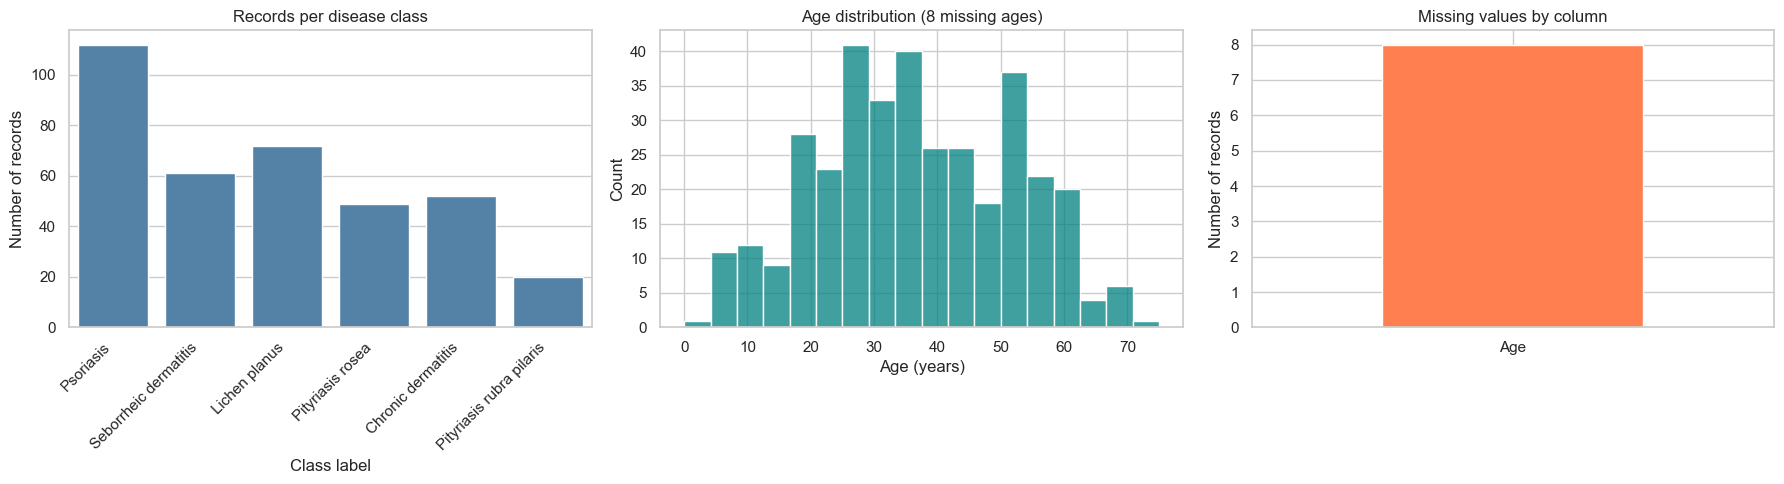

Descriptive statistics for numeric features:


,count,mean,std,min,25%,50%,75%,max
erythema,366.0,2.068306,0.664753,0.0,2.0,2.0,2.00,3.0
scaling,366.0,1.795082,0.701527,0.0,1.0,2.0,2.00,3.0
definite_borders,366.0,1.549180,0.907525,0.0,1.0,2.0,2.00,3.0
itching,366.0,1.366120,1.138299,0.0,0.0,1.0,2.00,3.0
koebner_phenomenon,366.0,0.633880,0.908016,0.0,0.0,0.0,1.00,3.0
polygonal_papules,366.0,0.448087,0.957327,0.0,0.0,0.0,0.00,3.0
follicular_papules,366.0,0.166667,0.570588,0.0,0.0,0.0,0.00,3.0
oral_mucosal_involvement,366.0,0.377049,0.834147,0.0,0.0,0.0,0.00,3.0
knee_and_elbow_involvement,366.0,0.614754,0.982979,0.0,0.0,0.0,1.00,3.0
scalp_involvement,366.0,0.519126,0.905639,0.0,0.0,0.0,1.00,3.0


In [25]:
label_order = sorted(class_names)
label_order_present = [label for label in label_order if label in set(df[target_column].astype(int))]
display_names = [class_names[label] for label in label_order_present]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.countplot(
    data=df, x=target_column, order=label_order_present, color="steelblue", ax=axes[0]
)
axes[0].set_title("Records per disease class")
axes[0].set_xlabel("Class label")
axes[0].set_ylabel("Number of records")
axes[0].set_xticks(range(len(label_order_present)), display_names, rotation=45, ha="right")

sns.histplot(data=df, x="Age", bins=18, color="teal", ax=axes[1])
axes[1].set_title(f"Age distribution ({df['Age'].isna().sum()} missing ages)")
axes[1].set_xlabel("Age (years)")

missing_counts = df.isna().sum().loc[lambda counts: counts.gt(0)].sort_values(ascending=False)
if missing_counts.empty:
    axes[2].text(0.5, 0.5, "No missing values", ha="center", va="center")
    axes[2].set_axis_off()
else:
    missing_counts.plot(kind="bar", color="coral", ax=axes[2])
    axes[2].set_title("Missing values by column")
    axes[2].set_ylabel("Number of records")
    axes[2].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

print("Descriptive statistics for numeric features:")
display(df[feature_columns].describe().T)


### Initial observations

The data combines clinical assessment with histopathological findings. `Age` is the only expected continuous feature; most other findings are ordinal values, and family history is binary. The full model therefore assumes all listed predictor types are available. The clinical-only check later in this notebook is a separate exploratory experiment, not proof of an early-diagnosis system.


## 5. Separate predictors and target, then make a stratified holdout split

**Why:** The target is the disease class, while all other columns are candidate predictors. Stratification keeps the class proportions similar in training and test data. The test set is kept out of model selection so it can give a final, less-biased check.


In [26]:
X = df[feature_columns].copy()
y = df[target_column].astype(int)

unknown_labels = sorted(set(y) - set(class_names))
if unknown_labels:
    raise ValueError(f"Unexpected target labels: {unknown_labels}")
if len(feature_columns) != 34:
    warnings.warn(f"Expected 34 predictors from the brief; found {len(feature_columns)}.")

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y,
)
print(f"Training records: {len(X_train)}")
print(f"Held-out test records: {len(X_test)}")
print("Training class counts:")
display(y_train.value_counts().sort_index().rename("records").to_frame())


Training records: 292
Held-out test records: 74
Training class counts:


,records
class,
1,89
2,49
3,57
4,39
5,42
6,16


## 6. Define comparable model pipelines

**Why:** Median imputation is fitted separately inside each training fold, avoiding information leakage from validation/test rows. Standardization is useful for distance- and margin-based methods, but tree models do not need it. A majority-class dummy model provides a simple baseline.


In [27]:
def make_pipeline_for(classifier, scale=False):
    steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale:
        steps.append(("scaler", StandardScaler()))
    steps.append(("classifier", classifier))
    return Pipeline(steps)


models = {
    "Most-frequent baseline": make_pipeline_for(DummyClassifier(strategy="most_frequent")),
    "Logistic Regression": make_pipeline_for(
        LogisticRegression(max_iter=3000, class_weight="balanced", random_state=RANDOM_STATE),
        scale=True,
    ),
    "RBF SVM": make_pipeline_for(SVC(kernel="rbf", class_weight="balanced"), scale=True),
    "K-Nearest Neighbors": make_pipeline_for(KNeighborsClassifier(n_neighbors=5), scale=True),
    "Decision Tree": make_pipeline_for(
        DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE)
    ),
    "Random Forest": make_pipeline_for(
        RandomForestClassifier(
            n_estimators=300, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1
        )
    ),
    "Extra Trees": make_pipeline_for(
        ExtraTreesClassifier(
            n_estimators=300, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1
        )
    ),
    "Gradient Boosting": make_pipeline_for(
        GradientBoostingClassifier(random_state=RANDOM_STATE)
    ),
}
print(f"Models to compare (including the baseline): {len(models)}")


Models to compare (including the baseline): 8


## 7. Compare models with repeated stratified cross-validation

**Why:** A single split can give unstable results on a small dataset. Repeated stratified 5-fold CV provides 15 training-only validation scores per model. Accuracy is intuitive, while macro-F1 weights each disease class equally and is more informative when class sizes differ. The winner is selected using mean CV macro-F1 only.


In [28]:
cv = RepeatedStratifiedKFold(
    n_splits=5, n_repeats=3, random_state=RANDOM_STATE
)
scoring = {"accuracy": "accuracy", "macro_f1": "f1_macro"}
cv_rows = []

for model_name, pipeline in models.items():
    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        error_score="raise",
    )
    cv_rows.append({
        "model": model_name,
        "cv_accuracy_mean": scores["test_accuracy"].mean(),
        "cv_accuracy_std": scores["test_accuracy"].std(),
        "cv_macro_f1_mean": scores["test_macro_f1"].mean(),
        "cv_macro_f1_std": scores["test_macro_f1"].std(),
    })

cv_results = pd.DataFrame(cv_rows).sort_values(
    ["cv_macro_f1_mean", "cv_accuracy_mean"], ascending=False
).reset_index(drop=True)
print(cv_results.round(3).to_string(index=False))

winner_name = cv_results.loc[0, "model"]
winner_cv_macro_f1 = cv_results.loc[0, "cv_macro_f1_mean"]
print(f"Selected by training CV macro-F1: {winner_name}")


                 model  cv_accuracy_mean  cv_accuracy_std  cv_macro_f1_mean  cv_macro_f1_std
           Extra Trees             0.983            0.011             0.981            0.012
               RBF SVM             0.979            0.014             0.977            0.016
   Logistic Regression             0.975            0.020             0.972            0.022
         Random Forest             0.977            0.016             0.971            0.023
   K-Nearest Neighbors             0.968            0.019             0.964            0.022
     Gradient Boosting             0.959            0.022             0.951            0.029
         Decision Tree             0.949            0.020             0.943            0.028
Most-frequent baseline             0.305            0.006             0.078            0.001
Selected by training CV macro-F1: Extra Trees


## 8. Evaluate the selected model on the held-out test set

**Why:** This is the one final evaluation after model selection. The held-out rows were not used to choose the winner or fit preprocessing. Per-class scores and a confusion matrix show which diagnoses are confused, which overall accuracy alone can hide.


Selected model: Extra Trees
Training CV macro-F1: 0.981
Held-out accuracy: 0.973
Held-out macro precision: 0.972
Held-out macro recall: 0.972
Held-out macro-F1: 0.970


,precision,recall,f1-score,support
1: Psoriasis,1.000,1.000,1.000,23.000
2: Seborrheic dermatitis,1.000,0.833,0.909,12.000
3: Lichen planus,1.000,1.000,1.000,15.000
4: Pityriasis rosea,0.833,1.000,0.909,10.000
5: Chronic dermatitis,1.000,1.000,1.000,10.000
6: Pityriasis rubra pilaris,1.000,1.000,1.000,4.000
accuracy,0.973,0.973,0.973,0.973
macro avg,0.972,0.972,0.970,74.000
weighted avg,0.977,0.973,0.973,74.000


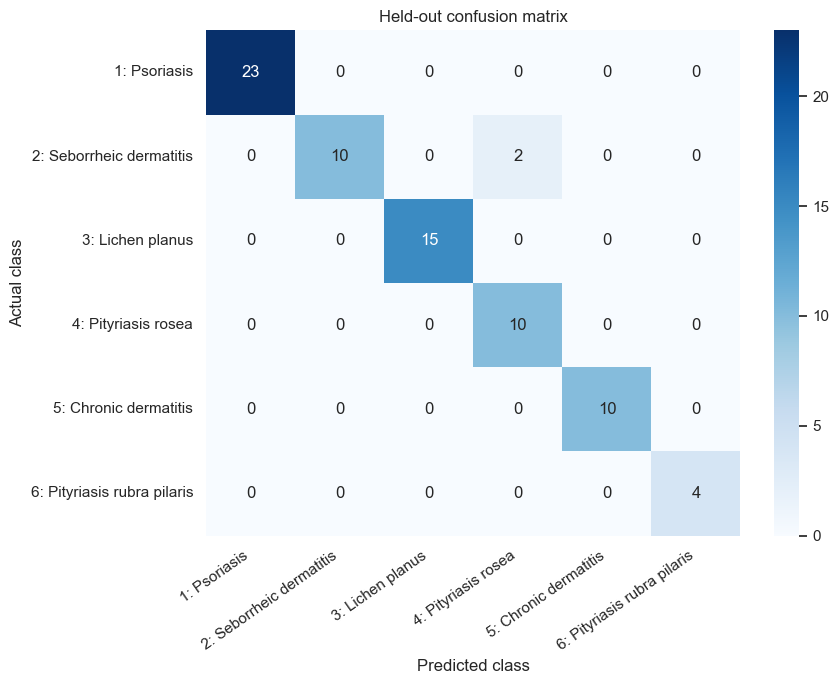

In [29]:
final_model = clone(models[winner_name])
final_model.fit(X_train, y_train)
test_predictions = final_model.predict(X_test)
labels = sorted(class_names)
label_text = [f"{label}: {class_names[label]}" for label in labels]

test_accuracy = accuracy_score(y_test, test_predictions)
test_macro_f1 = f1_score(y_test, test_predictions, average="macro", zero_division=0)
test_macro_precision = precision_score(
    y_test, test_predictions, average="macro", zero_division=0
)
test_macro_recall = recall_score(
    y_test, test_predictions, average="macro", zero_division=0
)
print(f"Selected model: {winner_name}")
print(f"Training CV macro-F1: {winner_cv_macro_f1:.3f}")
print(f"Held-out accuracy: {test_accuracy:.3f}")
print(f"Held-out macro precision: {test_macro_precision:.3f}")
print(f"Held-out macro recall: {test_macro_recall:.3f}")
print(f"Held-out macro-F1: {test_macro_f1:.3f}")

report = classification_report(
    y_test,
    test_predictions,
    labels=labels,
    target_names=label_text,
    output_dict=True,
    zero_division=0,
)
display(pd.DataFrame(report).T.round(3))

matrix = confusion_matrix(y_test, test_predictions, labels=labels)
plt.figure(figsize=(9, 7))
sns.heatmap(
    matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_text,
    yticklabels=label_text,
)
plt.title("Held-out confusion matrix")
plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


## 9. Exploratory clinical-only comparison

**Why:** The full classifier includes histopathology, which may require a biopsy. To make the early-identification discussion more honest, compare two models using only the 11 clinical signs plus Age. This is an exploratory training-CV comparison; it does not establish clinical readiness or replace a clinician's assessment.


In [30]:
clinical_features = [
    "erythema", "scaling", "definite_borders", "itching",
    "koebner_phenomenon", "polygonal_papules", "follicular_papules",
    "oral_mucosal_involvement", "knee_and_elbow_involvement",
    "scalp_involvement", "family_history", "Age",
]
clinical_models = {
    "Clinical-only RBF SVM": make_pipeline_for(
        SVC(kernel="rbf", class_weight="balanced"), scale=True
    ),
    "Clinical-only Extra Trees": make_pipeline_for(
        ExtraTreesClassifier(
            n_estimators=300, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1
        )
    ),
}
clinical_rows = []
for model_name, pipeline in clinical_models.items():
    scores = cross_validate(
        pipeline,
        X_train[clinical_features],
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        error_score="raise",
    )
    clinical_rows.append({
        "model": model_name,
        "cv_accuracy_mean": scores["test_accuracy"].mean(),
        "cv_accuracy_std": scores["test_accuracy"].std(),
        "cv_macro_f1_mean": scores["test_macro_f1"].mean(),
        "cv_macro_f1_std": scores["test_macro_f1"].std(),
    })

clinical_results = pd.DataFrame(clinical_rows).sort_values(
    "cv_macro_f1_mean", ascending=False
).reset_index(drop=True)
print(clinical_results.round(3).to_string(index=False))
print(
    "Compare these CV results with the full-feature results cautiously: "
    "this is a small dataset and neither experiment is external clinical validation."
)


                    model  cv_accuracy_mean  cv_accuracy_std  cv_macro_f1_mean  cv_macro_f1_std
Clinical-only Extra Trees             0.871            0.025             0.861            0.029
    Clinical-only RBF SVM             0.861            0.036             0.858            0.035
Compare these CV results with the full-feature results cautiously: this is a small dataset and neither experiment is external clinical validation.


## 10. Inspect model behavior with permutation importance

**Why:** Permutation importance measures how much the selected model's held-out macro-F1 changes when one feature is shuffled. It is model-specific and associative, not a causal explanation. The test set is used here only for descriptive interpretation, not to change the selected model.


,feature,importance_mean,importance_std
14,fibrosis_of_the_papillary_dermis,0.0659,0.0209
25,disappearance_of_the_granular_layer,0.0423,0.0160
4,koebner_phenomenon,0.0351,0.0182
27,spongiosis,0.0190,0.0125
20,elongation_of_the_rete_ridges,0.0132,0.0078
19,clubbing_of_the_rete_ridges,0.0128,0.0145
13,PNL_infiltrate,0.0116,0.0125
16,acanthosis,0.0107,0.0070
18,parakeratosis,0.0107,0.0070
8,knee_and_elbow_involvement,0.0088,0.0094


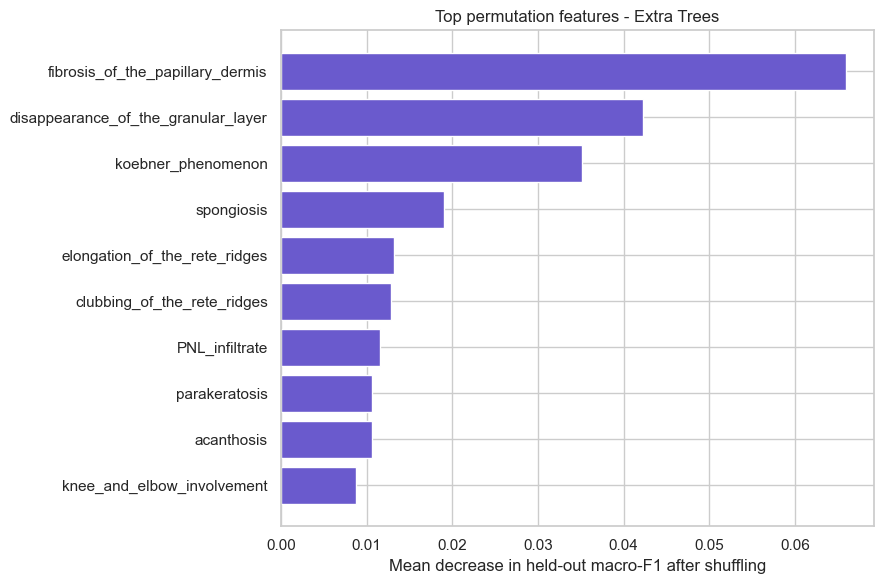

In [31]:
importance = permutation_importance(
    final_model,
    X_test,
    y_test,
    scoring="f1_macro",
    n_repeats=10,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
importance_table = pd.DataFrame({
    "feature": feature_columns,
    "importance_mean": importance.importances_mean,
    "importance_std": importance.importances_std,
}).sort_values("importance_mean", ascending=False)
display(importance_table.head(10).round(4))

top_importance = importance_table.head(10).sort_values("importance_mean")
plt.figure(figsize=(9, 6))
plt.barh(top_importance["feature"], top_importance["importance_mean"], color="slateblue")
plt.xlabel("Mean decrease in held-out macro-F1 after shuffling")
plt.title(f"Top permutation features - {winner_name}")
plt.tight_layout()
plt.show()


## 11. Report on challenges faced

During this project, the main challenges were the limited size and uneven class distribution of the dataset, a small amount of missing Age data, mixed feature scales, and the combination of clinical and biopsy-derived measurements. The approaches below were chosen to address these issues without hiding the remaining uncertainty.

**Why this report is included:** documenting the data issue, its effect on the analysis, the technique applied, and its reason makes the modeling decisions reproducible and easier to assess.

In [32]:
challenge_table = pd.DataFrame([
    {
        "challenge observed in the data": "Limited dataset size",
        "evidence and impact": f"There are {len(df)} records for six classes. With few examples, one random split could give an unstable estimate.",
        "technique used and reason": "Used an 80/20 train-test split and repeated stratified 5-fold cross-validation (3 repeats). Repetition compares models across multiple training folds instead of relying on one validation split.",
        "remaining limitation": "Repeated folds still reuse this same small dataset; they are not independent external validation.",
    },
    {
        "challenge observed in the data": "Unequal representation of disease classes",
        "evidence and impact": f"The largest class has {class_counts.max()} records and the smallest has {class_counts.min()}; a model could perform well overall while missing a less common class.",
        "technique used and reason": "Stratified splitting keeps class proportions similar. Macro-F1 gives each class equal weight, and class_weight='balanced' is used for selected classifiers to reduce majority-class bias.",
        "remaining limitation": "The rarest class remains uncertain because it has few examples, especially in the held-out test set.",
    },
    {
        "challenge observed in the data": "Missing Age values",
        "evidence and impact": f"Age has {df['Age'].isna().sum()} missing values; dropping these rows would discard observations and could further reduce small classes.",
        "technique used and reason": "Applied median imputation within each model pipeline. This retains rows, is simple for numeric Age, and learns the imputation value from the training fold only to prevent leakage.",
        "remaining limitation": "An imputed age is an estimate and may not reflect the missing patient's true age.",
    },
    {
        "challenge observed in the data": "Different feature scales and meanings",
        "evidence and impact": "Most findings are ordinal 0-3, family history is binary, and Age is continuous; distance-based and margin-based models can be affected by scale.",
        "technique used and reason": "Standardized features for Logistic Regression, RBF SVM, and KNN, which are scale-sensitive. Kept tree-based models unscaled because their split rules do not require standardization.",
        "remaining limitation": "Encoding ordinal findings as numbers assumes their ordering is meaningful; numeric gaps may not represent equal clinical differences.",
    },
    {
        "challenge observed in the data": "Clinical signs and biopsy-derived features are mixed",
        "evidence and impact": "The full predictor set includes histopathological attributes, which may not be available during an initial clinical examination.",
        "technique used and reason": "Reported the full-feature model and separately evaluated models with the 11 clinical attributes plus Age. This shows how available inputs affect results without presenting the full model as a pre-biopsy tool.",
        "remaining limitation": "The clinical-only comparison is exploratory and has not been validated in a real early-screening workflow.",
    },
    {
        "challenge observed in the data": "No independent external dataset",
        "evidence and impact": "Only the supplied dataset is available, so performance in other hospitals, populations, or time periods cannot be measured here.",
        "technique used and reason": "Reserved a stratified holdout for a final within-dataset check and report the limitation explicitly rather than claiming generalization.",
        "remaining limitation": "The held-out records come from the same source as training data; prospective, multi-site validation is still required.",
    },
    {
        "challenge observed in the data": "High risk of overly optimistic evaluation",
        "evidence and impact": "Imputation, scaling, or model choice performed using all rows could leak information from validation/test records into training.",
        "technique used and reason": "Placed imputation and scaling inside scikit-learn pipelines, selected the model using training-only cross-validation, and used the holdout only for final reporting.",
        "remaining limitation": "The holdout is small; its score can vary, and repeated experimentation on it would weaken its independence.",
    },
])
display(challenge_table)


,challenge observed in the data,evidence and impact,technique used and reason,remaining limitation
0,Limited dataset size,There are 366 records for six classes. With fe...,Used an 80/20 train-test split and repeated st...,Repeated folds still reuse this same small dat...
1,Unequal representation of disease classes,The largest class has 112 records and the smal...,Stratified splitting keeps class proportions s...,The rarest class remains uncertain because it ...
2,Missing Age values,Age has 8 missing values; dropping these rows ...,Applied median imputation within each model pi...,An imputed age is an estimate and may not refl...
3,Different feature scales and meanings,"Most findings are ordinal 0-3, family history ...","Standardized features for Logistic Regression,...",Encoding ordinal findings as numbers assumes t...
4,Clinical signs and biopsy-derived features are...,The full predictor set includes histopathologi...,Reported the full-feature model and separately...,The clinical-only comparison is exploratory an...
5,No independent external dataset,"Only the supplied dataset is available, so per...",Reserved a stratified holdout for a final with...,The held-out records come from the same source...
6,High risk of overly optimistic evaluation,"Imputation, scaling, or model choice performed...",Placed imputation and scaling inside scikit-le...,"The holdout is small; its score can vary, and ..."


## 12. Final model comparison report and recommendation

**Why:** Translate measured results into a short decision while separating the best model in this experiment from a model that is ready for patient care. The recommendation is generated from the metrics calculated above, not from hard-coded scores.


In [33]:
print("FINAL PROJECT REPORT")
print("=" * 72)
print(f"Dataset: {len(df)} rows; {len(feature_columns)} input features; {y.nunique()} classes.")
print(f"Age values imputed by the pipeline: {df['Age'].isna().sum()}.")
print(f"Training-only CV winner (mean macro-F1): {winner_name} ({winner_cv_macro_f1:.3f}).")
print(
    f"One-time held-out result: accuracy={test_accuracy:.3f}, "
    f"macro-F1={test_macro_f1:.3f}, macro-recall={test_macro_recall:.3f}."
)
print()
print("Recommendation:")
print(
    f"{winner_name} is the leading candidate among the tested pipelines on this "
    "dataset, based on training cross-validation macro-F1. Treat it as an "
    "educational decision-support prototype only, not a production diagnostic system."
)
print()
print("Before any clinical use, require:")
print("- Independent, prospective, multi-site validation on representative patients.")
print("- Per-class performance, subgroup/fairness checks, calibration, and uncertainty review.")
print("- A clinician-approved workflow, clear missing-input policy, and human oversight.")
print("- Privacy/security review, ongoing drift monitoring, and applicable regulatory review.")
print(
    "The dataset is small and the smallest class has limited examples; one holdout "
    "score can vary substantially. Do not promise that these results will transfer "
    "to a different population or setting."
)


FINAL PROJECT REPORT
Dataset: 366 rows; 34 input features; 6 classes.
Age values imputed by the pipeline: 8.
Training-only CV winner (mean macro-F1): Extra Trees (0.981).
One-time held-out result: accuracy=0.973, macro-F1=0.970, macro-recall=0.972.

Recommendation:
Extra Trees is the leading candidate among the tested pipelines on this dataset, based on training cross-validation macro-F1. Treat it as an educational decision-support prototype only, not a production diagnostic system.

Before any clinical use, require:
- Independent, prospective, multi-site validation on representative patients.
- Per-class performance, subgroup/fairness checks, calibration, and uncertainty review.
- A clinician-approved workflow, clear missing-input policy, and human oversight.
- Privacy/security review, ongoing drift monitoring, and applicable regulatory review.
The dataset is small and the smallest class has limited examples; one holdout score can vary substantially. Do not promise that these results 

## 13. Practical suggestions for clinicians (research workflow only)

1. Continue a careful history and skin examination; these six disorders can share visible features.
2. Record clinical signs consistently and consider age and family history where clinically appropriate.
3. When clinically indicated, use histopathology and specialist review as part of the differential diagnosis.
4. A future validated tool could provide a ranked list of possibilities and flag uncertainty for clinician review; it must not make autonomous decisions or delay referral.
5. Validate a clinical-only pathway separately before claiming it can support assessment before biopsy. This notebook's clinical-only experiment is not evidence of safety or clinical effectiveness.
6. Keep an expert responsible for the final diagnosis and treatment plan.

These are general project recommendations, not patient-specific medical advice.


## 14. Conclusion and references

This analysis checks data quality, visualizes the target and missing values, compares a dummy baseline and seven classifiers, selects a candidate using repeated stratified cross-validation, and reports its held-out metrics. It also tests a clinical-only feature subset to show why full-feature performance should not be equated with a pre-biopsy screen.


